# 04 · La feature y el detector

**Pregunta de este notebook.** ¿La potencia cruzada entre la serie RR y la EDR en la banda de la apnea es mayor en los minutos con apnea, y alcanza un único umbral para detectarlos? Es la hipótesis del trabajo (`docs/objetivos_hipotesis.md`):

- **Predicción 1**: dentro de cada noche, F es mayor en los minutos con apnea (AUC dentro de la noche > 0,5).
- **Predicción 2**: con un umbral fijado en desarrollo, F detecta los minutos con apnea (AUC > 0,5 con todos los minutos juntos; se informan sensibilidad y especificidad).
- **Pregunta secundaria**: ¿la EDR aporta algo que no esté en la serie RR sola?

Todo con los registros de desarrollo. Lo único que se ajusta acá es el **umbral**; la banda (0,01–0,05 Hz) salió del espectro con y sin apnea (`01`) y la ventana (240 s) de la resolución que hace falta para verla. Test se evalúa una sola vez en `05`, con todo lo de este notebook fijo.

In [1]:
import sys
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import detrend
from scipy.stats import rankdata, spearmanr

from src.config import SPLIT_CSV
from src.data import load_apnea_labels
from src.features.build import record_series
from src.features.coupling import welch_spectra
from src.features.lomb import lomb_psd
from src.features.windows import centered_windows
from src.qrs.rr_clean import minute_quality
from src.viz.plots import ANCHO, APNEA, COLORES_CAT, GRIS, NORMAL, label_strip, save, setup

setup()
split = pd.read_csv(SPLIT_CSV)
DEV = split[split.set == "dev"].record.tolist()
SUJETO = split.set_index("record").subject
FSU, W, BANDA = 2.0, 240, (0.01, 0.05)
F_LOMB = np.arange(0.01, 0.0501, 0.0025)

## 1. La feature

Para cada minuto se toma una ventana de 240 s centrada en él, con la serie RR y la EDR interpoladas a 2 Hz (`02`, `03`). En esa ventana se estima, por el método de Welch (3 segmentos de 120 s, ventana de Hann, 50 % de solapamiento):

- el espectro del RR, S_RR(f), y el de la EDR, S_EDR(f): cuánta potencia tiene cada señal en cada frecuencia;
- el **espectro cruzado**, S_RR,EDR(f) = promedio sobre segmentos de X_RR(f)* · X_EDR(f), donde X son las transformadas de Fourier de cada segmento. Su módulo es grande en las frecuencias donde **las dos señales oscilan a la vez y con una relación de fase que se repite** de un segmento a otro; si oscilan sin relación, los productos de los segmentos tienen fases al azar y se cancelan al promediar.

**F = log₁₀ del módulo del espectro cruzado promediado en 0,01–0,05 Hz.** Se usa el logaritmo porque la potencia varía en órdenes de magnitud entre minutos y personas. Para la pregunta secundaria se calculan, con la misma ventana y la misma banda:

- **RR solo (Welch)**: log₁₀ de S_RR en la banda. Es la comparación justa con F: mismo estimador, solo falta la EDR.
- **RR solo (Lomb)**: la potencia del RR en la banda estimada con el periodograma de Lomb sobre los latidos, sin interpolar. Es la forma estándar de estimar el espectro de la variabilidad cardíaca (Task Force, 1996) cuando la serie no está muestreada a intervalos regulares.
- **EDR sola**: log₁₀ de S_EDR en la banda.

Se evalúan los minutos con etiqueta y con 20 % o menos de RR corregidos.

In [2]:
def features_registro(rec):
    s = record_series(rec)
    lab = load_apnea_labels(rec)
    q = minute_quality(s["t_rr"], s["corrected"], len(lab))
    t = s["t"]
    minutos, inicios = centered_windows(len(lab), W, t[0], t[-1] + 1 / FSU)
    n = int(W * FSU); filas = []
    for m, a in zip(minutos, inicios):
        i = int(round((a - t[0]) * FSU)); x, y = s["rr"][i:i + n], s["edr"][i:i + n]
        if len(x) < n:
            continue
        f, sxx, syy, sxy = welch_spectra(x, y, FSU, n // 2)
        b = (f >= BANDA[0] - 1e-9) & (f <= BANDA[1] + 1e-9)
        sel = (s["t_rr"] >= a) & (s["t_rr"] < a + W)
        lomb = np.log10(lomb_psd(s["t_rr"][sel], detrend(s["rr_beats"][sel]), F_LOMB).mean()) if sel.sum() > 20 else np.nan
        filas.append({"record": rec, "minute": m, "label": int(lab[m]), "q": q[m],
                      "F": np.log10(np.abs(sxy[b]).mean()), "RR (Welch)": np.log10(sxx[b].mean()),
                      "RR (Lomb)": lomb, "EDR": np.log10(syy[b].mean())})
    return filas

with ProcessPoolExecutor(4) as ex:
    tab = pd.DataFrame([f_ for fs_ in ex.map(features_registro, DEV) for f_ in fs_])
FEATS = ["F", "RR (Welch)", "RR (Lomb)", "EDR"]
ev = tab[(tab.label >= 0) & (tab.q <= 0.2)].dropna().reset_index(drop=True)
ev["subject"] = ev.record.map(SUJETO)
print(f"{len(ev)} minutos de evaluación en {ev.record.nunique()} registros ({ev.subject.nunique()} personas); "
      f"{100 * ev.label.mean():.1f} % con apnea; quedan afuera {len(tab) - len(ev)} minutos sin etiqueta o con > 20 % de RR corregidos")

22772 minutos de evaluación en 47 registros (19 personas); 40.2 % con apnea; quedan afuera 135 minutos sin etiqueta o con > 20 % de RR corregidos


## 2. Cómo se ve en una noche

Antes de medir, se mira la feature a lo largo de una noche con apnea y tramos normales (`a03`).

PosixPath('/home/user/TP-PSB-G8/informe/figuras/04_noche_a03.png')

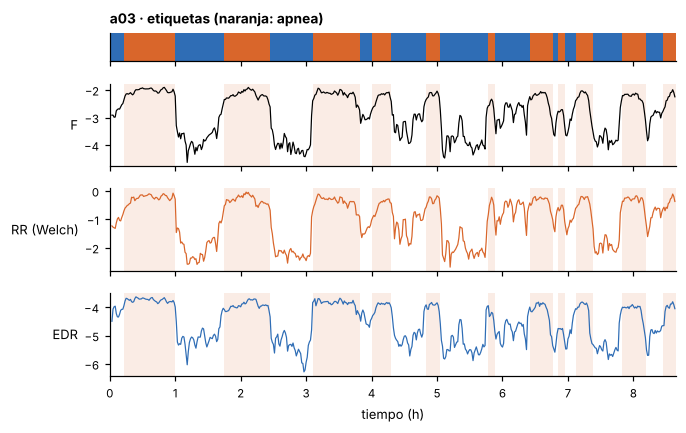

In [3]:
g = tab[tab.record == "a03"].set_index("minute")
lab03 = load_apnea_labels("a03")
fig, axs = plt.subplots(4, 1, figsize=(ANCHO, 4.0), sharex=True, gridspec_kw={"height_ratios": [0.35, 1, 1, 1]})
label_strip(axs[0], lab03, unit=60); axs[0].set_title("a03 · etiquetas (naranja: apnea)")
for ax, col, color in ((axs[1], "F", "black"), (axs[2], "RR (Welch)", APNEA), (axs[3], "EDR", NORMAL)):
    ax.plot(g.index / 60, g[col], color=color, lw=0.8)
    ax.set_ylabel(col, rotation=0, ha="right", va="center")
    for a_, b_ in zip(*[np.flatnonzero(np.diff(np.r_[0, (lab03 == 1).astype(int), 0]))[k::2] for k in (0, 1)]):
        ax.axvspan(a_ / 60, b_ / 60, color=APNEA, alpha=0.12, lw=0)
axs[-1].set_xlabel("tiempo (h)")
fig.tight_layout()
save(fig, "04_noche_a03")

**Qué se ve.** En los tramos con apnea (sombreados) F sube y se mantiene alta; en los tramos normales baja. El RR y la EDR por separado muestran el mismo patrón, con más variación dentro de cada tramo.

## 3. Predicción 1: dentro de cada noche

En los 31 registros de desarrollo con al menos 20 minutos de cada tipo se calcula el **AUC dentro de la noche**: la probabilidad de que un minuto con apnea elegido al azar tenga un valor mayor que un minuto normal elegido al azar **de la misma noche** (0,5 es azar, 1 es separación perfecta). Así no influye que una persona tenga más variabilidad o más apnea que otra.

,AUC dentro de la noche (mediana),"registros con AUC > 0,5",F − esta (media),IC 95 %,registros donde gana F
feature,,,,,
F,0.882,31/31,NaN,NaN,NaN
RR (Welch),0.924,31/31,-0.029,-0.043 a -0.009,5/31
RR (Lomb),0.912,30/31,-0.012,-0.027 a +0.010,10/31
EDR,0.810,31/31,0.075,+0.041 a +0.109,29/31


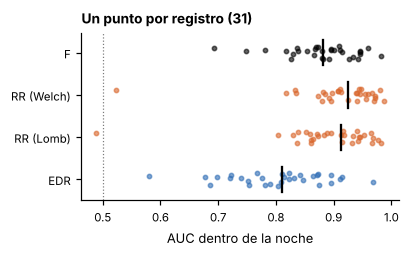

In [4]:
def auc(x, y):
    r = rankdata(x); n1 = int(y.sum()); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

dentro = []
for rec, gr in ev.groupby("record"):
    y = gr.label.to_numpy()
    if (y == 1).sum() >= 20 and (y == 0).sum() >= 20:
        dentro.append({"record": rec, "subject": SUJETO[rec], **{f_: auc(gr[f_].to_numpy(), y) for f_ in FEATS}})
dentro = pd.DataFrame(dentro)

rng = np.random.default_rng(2026)
def ic_pareado(d, suj, n=4000):
    us = np.unique(suj)
    boot = [np.mean(np.concatenate([d[suj == u] for u in rng.choice(us, len(us))])) for _ in range(n)]
    return np.percentile(boot, [2.5, 97.5])

filas = []
for f_ in FEATS:
    v = dentro[f_].to_numpy()
    fila = {"feature": f_, "AUC dentro de la noche (mediana)": np.median(v),
            "registros con AUC > 0,5": f"{int((v > 0.5).sum())}/{len(v)}"}
    if f_ != "F":
        d = dentro["F"].to_numpy() - v
        lo, hi = ic_pareado(d, dentro.subject.to_numpy())
        fila.update({"F − esta (media)": d.mean(), "IC 95 %": f"{lo:+.3f} a {hi:+.3f}", "registros donde gana F": f"{int((d > 0).sum())}/{len(d)}"})
    filas.append(fila)
tabla_dentro = pd.DataFrame(filas).set_index("feature")

fig, ax = plt.subplots(figsize=(ANCHO * 0.6, 2.4))
for y_, f_ in enumerate(FEATS[::-1]):
    v = dentro[f_]
    ax.scatter(v, np.full(len(v), y_) + np.random.default_rng(0).uniform(-0.15, 0.15, len(v)), s=8,
               color="black" if f_ == "F" else (APNEA if f_.startswith("RR") else NORMAL), alpha=0.6)
    ax.plot([v.median()] * 2, [y_ - 0.3, y_ + 0.3], color="black", lw=1.5)
ax.axvline(0.5, color=GRIS, ls=":", lw=0.8)
ax.set_yticks(range(len(FEATS))); ax.set_yticklabels(FEATS[::-1])
ax.set(xlabel="AUC dentro de la noche", title="Un punto por registro (31)")
fig.tight_layout()
save(fig, "04_auc_dentro")
tabla_dentro.round(3)

**Qué se ve.**
- **La predicción 1 se cumple**: F es mayor en los minutos con apnea en los 31 registros, con un AUC mediano cercano a 0,9.
- Pero **dentro de una noche, el RR solo separa mejor que F**: la diferencia es negativa y su intervalo no incluye el cero. Sumar la EDR, que es más ruidosa, le resta al RR cuando se comparan minutos de una misma persona.

## 4. Predicción 2: un umbral para todos

El detector usa **un único umbral** para todas las personas, así que importa cómo separa los minutos de todos los registros juntos. La curva ROC muestra, para cada umbral posible, la sensibilidad (fracción de minutos con apnea detectados) contra 1 − especificidad (fracción de minutos normales marcados como apnea). El AUC es el área bajo esa curva. El intervalo de confianza se calcula remuestreando **personas** (2000 veces), porque los minutos de una misma noche no son independientes (`01`).

F − RR (Welch), todos los minutos: +0.064 (IC 95 % -0.010 a +0.150)


,AUC (todos los minutos),IC 95 %
feature,,
F,0.879,0.813 a 0.938
RR (Welch),0.815,0.712 a 0.906
RR (Lomb),0.793,0.686 a 0.885
EDR,0.828,0.741 a 0.902


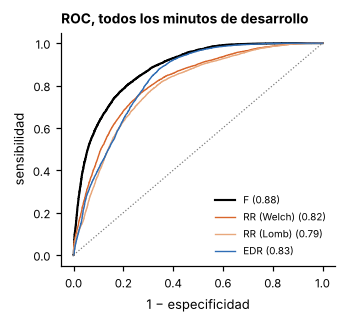

In [5]:
def roc(x, y):
    o = np.argsort(-x); y_ = y[o]
    tpr = np.r_[0, np.cumsum(y_) / y_.sum()]; fpr = np.r_[0, np.cumsum(1 - y_) / (1 - y_).sum()]
    return fpr, tpr

subj = ev.subject.to_numpy(); us = np.unique(subj)
idx_por_suj = {u: np.flatnonzero(subj == u) for u in us}
boot_idx = [np.concatenate([idx_por_suj[u] for u in rng.choice(us, len(us))]) for _ in range(2000)]
y_all = ev.label.to_numpy()
filas = []
fig, ax = plt.subplots(figsize=(3.2, 3.0))
for f_, color in zip(FEATS, ["black", APNEA, "#E8A87C", NORMAL]):
    x_all = ev[f_].to_numpy()
    a_ = auc(x_all, y_all)
    bs = np.array([auc(x_all[i], y_all[i]) for i in boot_idx])
    filas.append({"feature": f_, "AUC (todos los minutos)": a_, "IC 95 %": f"{np.percentile(bs, 2.5):.3f} a {np.percentile(bs, 97.5):.3f}"})
    fpr, tpr = roc(x_all, y_all)
    ax.plot(fpr, tpr, color=color, lw=1.4 if f_ == "F" else 0.9, label=f"{f_} ({a_:.2f})")
ax.plot([0, 1], [0, 1], color=GRIS, ls=":", lw=0.8)
ax.set(xlabel="1 − especificidad", ylabel="sensibilidad", title="ROC, todos los minutos de desarrollo")
ax.legend(loc="lower right", fontsize=6.5)
fig.tight_layout()
save(fig, "04_roc")
d_pool = np.array([auc(ev["F"].to_numpy()[i], y_all[i]) - auc(ev["RR (Welch)"].to_numpy()[i], y_all[i]) for i in boot_idx[:1000]])
print(f"F − RR (Welch), todos los minutos: {auc(ev['F'].to_numpy(), y_all) - auc(ev['RR (Welch)'].to_numpy(), y_all):+.3f} "
      f"(IC 95 % {np.percentile(d_pool, 2.5):+.3f} a {np.percentile(d_pool, 97.5):+.3f})")
pd.DataFrame(filas).set_index("feature").round(3)

**Qué se ve.** **La predicción 2 se cumple**: con todos los minutos juntos F separa bien (AUC claramente por encima de 0,5). Y acá el orden se invierte: **F queda por encima del RR solo** (+0,06 de AUC), aunque con 19 personas el intervalo de la diferencia incluye el cero (se imprime arriba): no se puede afirmar que lo supere.

## 5. Por qué el resultado depende del nivel de análisis

Dentro de una noche gana el RR; con todas las noches juntas F queda arriba. La diferencia tiene que venir de algo que cambia **entre personas**. Para verlo se compara, en cada registro, el valor medio de cada feature con su fracción de minutos con apnea, primero con todos los minutos y después solo con los **minutos normales**.

,todos los minutos,solo minutos normales
F,0.77,0.49
RR (Welch),0.31,-0.35
RR (Lomb),0.27,-0.33
EDR,0.70,0.63


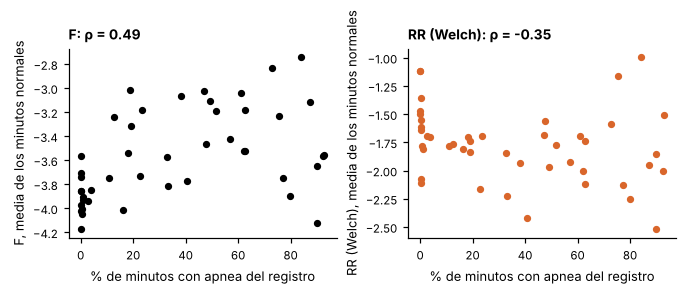

In [6]:
por_reg = ev.groupby("record").agg(frac=("label", "mean"), **{f_: (f_, "mean") for f_ in FEATS})
normales = ev[ev.label == 0].groupby("record").agg(n=("label", "size"), **{f_: (f_, "mean") for f_ in FEATS})
normales = normales[normales.n >= 20].join(por_reg.frac)
fig, axs = plt.subplots(1, 2, figsize=(ANCHO, 2.6), sharey=False)
for ax, f_, color in ((axs[0], "F", "black"), (axs[1], "RR (Welch)", APNEA)):
    ax.scatter(100 * normales.frac, normales[f_], s=14, color=color)
    rho = spearmanr(normales[f_], normales.frac)[0]
    ax.set(xlabel="% de minutos con apnea del registro", ylabel=f"{f_}, media de los minutos normales",
           title=f"{f_}: ρ = {rho:.2f}")
fig.tight_layout()
save(fig, "04_nivel_persona")
pd.DataFrame({"todos los minutos": {f_: spearmanr(por_reg[f_], por_reg.frac)[0] for f_ in FEATS},
              "solo minutos normales": {f_: spearmanr(normales[f_], normales.frac)[0] for f_ in FEATS}}).round(2)

**Qué se ve.** En las personas con más apnea, **F es más alta incluso en sus minutos normales**; el RR no (incluso tiende a lo contrario). La EDR lleva un nivel propio de cada persona que acompaña a la cantidad de apnea. Con un umbral único eso ayuda: F no solo marca los minutos con apnea, también distingue a las personas que tienen mucha. Dentro de una noche, en cambio, ese nivel es constante y no ayuda.

**Respuesta a la pregunta secundaria:** la EDR aporta información **a nivel de persona** (entre noches), pero no para distinguir un minuto de otro dentro de la misma noche, donde el RR solo es mejor.

**Una advertencia.** No se sabe qué es ese nivel personal: puede ser fisiológico (respiración más irregular durante todo el sueño, eventos más leves que no llegan a marcarse como apnea en los minutos "normales"), o depender de la anatomía y de la posición de los electrodos. Si depende de rasgos de la persona, puede generalizar peor a gente distinta; test quedó con un IMC mayor que desarrollo (`01`). Se discute como limitación.

## 6. El umbral

Un minuto se clasifica como apnea si F supera un umbral. Se elige el que maximiza el **índice de Youden**, J = sensibilidad + especificidad − 1 (Youden, 1950): es el punto de la curva ROC más alejado de la diagonal del azar. Se usa porque no hay un motivo para preferir no perder apneas a no dar falsas alarmas: el detector no es un diagnóstico y no hay costos definidos para cada error (Fluss et al., 2005). Con 40 % de minutos con apnea en desarrollo, las dos clases tienen un tamaño parecido.

**Estimación honesta.** Si el umbral se elige y se evalúa con los mismos minutos, el resultado sale optimista. Por eso también se hace una **validación cruzada por personas**: las 19 personas de desarrollo se reparten en 5 grupos; para cada grupo, el umbral se elige con los otros 4 y se aplica a ese grupo. Así cada minuto se clasifica con un umbral que no vio a su persona.

umbral de Youden (todo desarrollo): F > -3.171; en los 5 grupos de la validación: -3.171, -3.148, -3.087, -3.171, -3.339


,sensibilidad,especificidad,exactitud
estimación,,,
umbral elegido con todo desarrollo,0.808 (0.632–0.943),0.779 (0.692–0.857),0.791 (0.725–0.852)
validación cruzada por personas,0.805 (0.621–0.944),0.773 (0.669–0.859),0.786 (0.718–0.850)


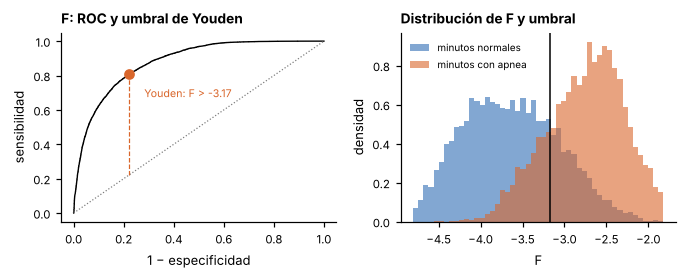

In [7]:
def youden(x, y):
    o = np.argsort(-x); xs, ys = x[o], y[o]
    tpr = np.cumsum(ys) / ys.sum(); fpr = np.cumsum(1 - ys) / (1 - ys).sum()
    k = int(np.argmax(tpr - fpr))
    return (xs[k] + xs[min(k + 1, len(xs) - 1)]) / 2

def metricas(y, pred):
    tp = int(((pred == 1) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    return {"sensibilidad": tp / (y == 1).sum(), "especificidad": tn / (y == 0).sum(), "exactitud": (tp + tn) / len(y)}

umbral = youden(ev["F"].to_numpy(), y_all)
grupos = np.array_split(np.random.default_rng(2026).permutation(us), 5)
pred_cv = np.zeros(len(ev), int); umbrales_cv = []
for gpo in grupos:
    te = np.isin(subj, gpo)
    u_ = youden(ev["F"].to_numpy()[~te], y_all[~te]); umbrales_cv.append(u_)
    pred_cv[te] = (ev["F"].to_numpy()[te] > u_).astype(int)
pred_todo = (ev["F"].to_numpy() > umbral).astype(int)
filas = []
for nombre, pred in (("umbral elegido con todo desarrollo", pred_todo), ("validación cruzada por personas", pred_cv)):
    m = metricas(y_all, pred)
    bs = [metricas(y_all[i], pred[i]) for i in boot_idx[:1000]]
    filas.append({"estimación": nombre, **{k: f"{v:.3f} ({np.percentile([b[k] for b in bs], 2.5):.3f}–{np.percentile([b[k] for b in bs], 97.5):.3f})"
                                          for k, v in m.items()}})
print(f"umbral de Youden (todo desarrollo): F > {umbral:.3f}; en los 5 grupos de la validación: "
      + ", ".join(f"{u_:.3f}" for u_ in umbrales_cv))

fpr, tpr = roc(ev["F"].to_numpy(), y_all)
m_ = metricas(y_all, pred_todo)
fig, ax = plt.subplots(1, 2, figsize=(ANCHO, 2.6))
ax[0].plot(fpr, tpr, color="black")
ax[0].plot(1 - m_["especificidad"], m_["sensibilidad"], "o", color=APNEA)
ax[0].annotate(f"Youden: F > {umbral:.2f}", (1 - m_["especificidad"], m_["sensibilidad"]), xytext=(10, -15),
               textcoords="offset points", fontsize=7, color=APNEA)
ax[0].plot([0, 1], [0, 1], color=GRIS, ls=":", lw=0.8)
ax[0].plot([1 - m_["especificidad"]] * 2, [1 - m_["especificidad"], m_["sensibilidad"]], color=APNEA, lw=0.8, ls="--")
ax[0].set(xlabel="1 − especificidad", ylabel="sensibilidad", title="F: ROC y umbral de Youden")
bins = np.linspace(ev.F.quantile(0.005), ev.F.quantile(0.995), 50)
ax[1].hist(ev.F[ev.label == 0], bins=bins, color=NORMAL, alpha=0.6, density=True, label="minutos normales")
ax[1].hist(ev.F[ev.label == 1], bins=bins, color=APNEA, alpha=0.6, density=True, label="minutos con apnea")
ax[1].axvline(umbral, color="black", lw=1)
ax[1].set(xlabel="F", ylabel="densidad", title="Distribución de F y umbral")
ax[1].legend(loc="upper left", fontsize=6.5)
fig.tight_layout()
save(fig, "04_umbral")
pd.DataFrame(filas).set_index("estimación")

**Qué se ve.** Los minutos con apnea tienen F más alta, pero las dos distribuciones se superponen: ningún umbral las separa del todo. Los umbrales de los 5 grupos de la validación son muy parecidos al elegido con todo desarrollo (es estable), y la validación cruzada da valores muy cercanos: el umbral no está sobreajustado.

## 7. Por noche

Además de cada minuto, interesa cuánta apnea se estima en cada noche: la **fracción de minutos clasificados como apnea** (con el umbral de la validación cruzada) contra la fracción real.

error medio (estimado − real): +5.8 puntos; controles (C): estimado medio 7.5 %


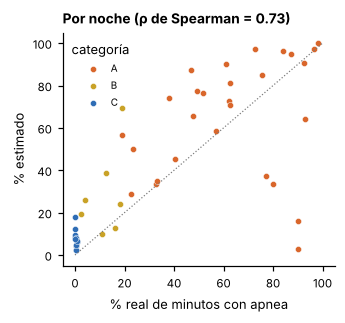

In [8]:
noche = ev.assign(pred=pred_cv).groupby("record").agg(real=("label", "mean"), estimada=("pred", "mean"))
noche = noche.join(split.set_index("record").category)
rho, _ = spearmanr(noche.real, noche.estimada)
fig, ax = plt.subplots(figsize=(3.2, 3.0))
for cat, gr in noche.groupby("category"):
    ax.scatter(100 * gr.real, 100 * gr.estimada, s=16, color=COLORES_CAT[cat], label=cat, edgecolor="white", lw=0.3)
ax.plot([0, 100], [0, 100], color=GRIS, ls=":", lw=0.8)
ax.set(xlabel="% real de minutos con apnea", ylabel="% estimado", title=f"Por noche (ρ de Spearman = {rho:.2f})")
ax.legend(loc="upper left", title="categoría", fontsize=6.5)
fig.tight_layout()
save(fig, "04_por_noche")
print(f"error medio (estimado − real): {100 * (noche.estimada - noche.real).mean():+.1f} puntos; "
      f"controles (C): estimado medio {100 * noche[noche.category == 'C'].estimada.mean():.1f} %")

**Qué se ve.** El detector ordena bastante bien las noches según cuánta apnea tienen, pero no las mide con exactitud. En las noches con poca apnea marca minutos de más (los controles quedan en promedio cerca del 8 %, cuando deberían estar en 0). Y hay **cuatro noches con 77–90 % de apnea donde marca muy poco**: son de solo dos personas (`a02` y `x14`; `a09` y `a18`). En ellas F sube durante la apnea, pero toda la noche queda por debajo del umbral: el nivel personal de F (sección 5) juega en contra. `a02` y `x14` tienen el QRS más chico de desarrollo (`01`).

## 8. Lo que queda fijo para test

| Qué | Valor |
|---|---|
| Feature | F = log₁₀ \|S_RR,EDR\| promediado en 0,01–0,05 Hz, Welch 3 × 120 s en una ventana de 240 s centrada en cada minuto |
| Preprocesamiento | `02` y `03` (detector propio, limpieza del RR, EDR por área con Wiener sin ectópicos ni atípicos) |
| Minutos evaluados | con etiqueta y con 20 % o menos de RR corregidos |
| Umbral | el de Youden con todo desarrollo (se imprime arriba) |
| Predicción 1 en test | AUC dentro de la noche de F > 0,5 en los registros de test con al menos 20 minutos de cada tipo |
| Predicción 2 en test | AUC con todos los minutos de test > 0,5, IC 95 % por bootstrap de personas; sensibilidad, especificidad y exactitud con el umbral fijo |
| Pregunta secundaria | F contra RR solo (Welch) en los dos niveles, descriptivo |

Esto se copia a `docs/objetivos_hipotesis.md` antes de abrir test.